In [8]:
import pandas as pd
import xarray as xr

from fast_o3_iv import utils, metrics
from fast_o3_iv.config import INTERIM_DATA_DIR
from fast_o3_iv.modeling.train import DatasetConfig


In [39]:
ramp_osdma8 = xr.open_dataset((
        INTERIM_DATA_DIR
        / "RAMP"
        / "Jacob_wRAMP_OSDMA8_1990_2017.nc"))


In [40]:
config = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical',
            variable_setname = 'setA',
            year_range = range(1975,2015)
        )
wa6_hist = utils.load_or_create_results_ds(
    "testing",
    "GPR-local",
    config,
)

Loading existing dataset from /home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/results/testing/NCAR/CESM2-WACCM6/historical/all/setA/GPR-local/NCAR.CESM2-WACCM6.historical.all.setA.testing.GPR-local.nc


In [30]:
#wa6_hist = utils.add_mda8o3_climatology(wa6_hist, config) # only required if target_var is an anomaly (setC)
wa6_hist_osdma8 = metrics.calc_osdma8(wa6_hist)

In [68]:
def get_bc_scaling_factor(model_osmda8_ds, obs_osdma8_ds):
    """get bias correction scaling factor"""
    
    baseline_years = slice("1990", "2014")

    obs = obs_osdma8_ds['ozone'] # osdma8

    ytrue = model_osmda8_ds["y_true"]
    ytrue_forced = ytrue.mean("ensemble_member") # ensemble means

    # baseline climatologies
    obs_base = obs.sel(time=baseline_years).mean("time")
    mod_base = ytrue_forced.sel(time=baseline_years).mean("time")

    # ratio-based bias-correction factor
    scaling_factor = obs_base / mod_base

    return scaling_factor.transpose("lat", "lon"), obs_base, mod_base

def bias_correct(model_osmda8_ds, scaling_factor):

    ytrue = model_osmda8_ds['y_true']
    ypred = model_osmda8_ds["y_pred"]

    ytrue_forced = ytrue.mean(dim='ensemble_member')
    ypred_forced = ypred.mean(dim='ensemble_member')
    
    ytrue_forced_bc = scaling_factor * ytrue_forced
    ypred_forced_bc = scaling_factor * ypred_forced
    # bias-correct y_true and y_pred
    ytrue_bc = ytrue_forced_bc + (ytrue - ytrue_forced)
    ypred_bc = ypred_forced_bc + (ypred - ypred_forced)

    # save back into a dataset
    model_osmda8_bc_ds = model_osmda8_ds.copy()
    model_osmda8_bc_ds["y_true_bc"] = ytrue_bc
    model_osmda8_bc_ds["y_pred_bc"] = ypred_bc
    model_osmda8_bc_ds["scaling_factor"] = scaling_factor

    return model_osmda8_bc_ds.transpose("time", "lat", "lon", "ensemble_member")

In [69]:
scaling_factor, obs_base, mod_base = get_bc_scaling_factor(wa6_hist_osdma8, ramp_osdma8)

In [70]:
wa6_hist_osdma8_bc = bias_correct(wa6_hist_osdma8, scaling_factor)

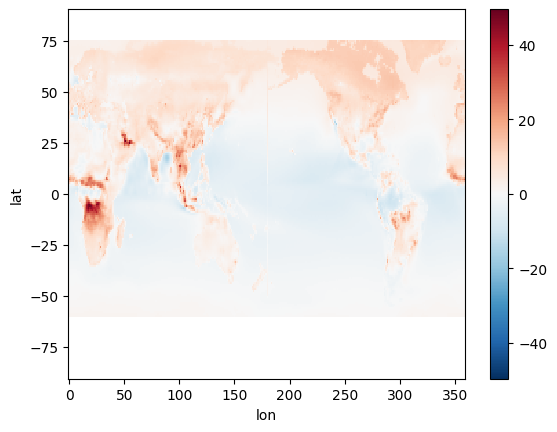

In [72]:
(mod_base-obs_base).plot()

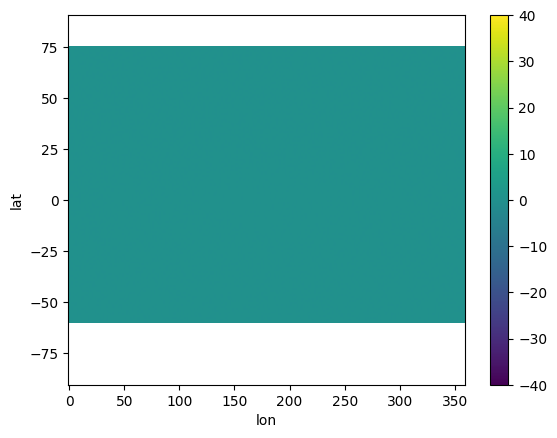

In [75]:
(wa6_hist_osdma8_bc['y_true_bc'].sel(time=slice("1990", "2014"))-obs_base).mean(dim=['time','ensemble_member']).plot(vmin=-40, vmax=40)

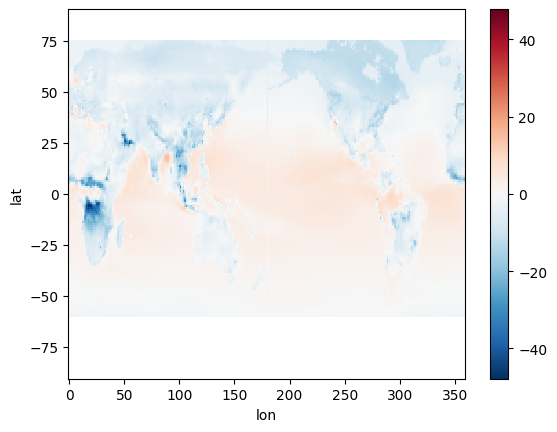

In [65]:
(wa6_hist_osdma8_bc['y_pred_bc']-wa6_hist_osdma8_bc['y_pred']).mean(dim=['time','ensemble_member']).plot()

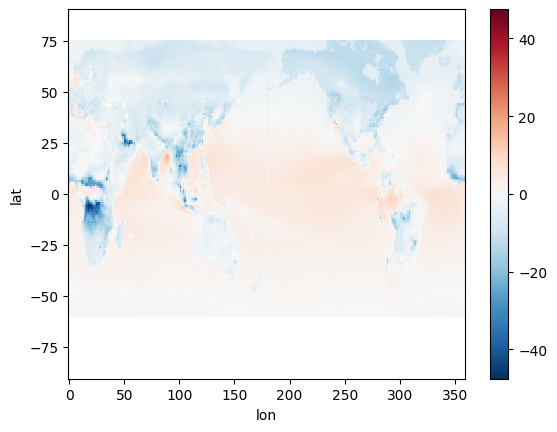

In [66]:
(wa6_hist_osdma8_bc['y_true_bc']-wa6_hist_osdma8_bc['y_true']).mean(dim=['time','ensemble_member']).plot()

In [ ]:
(wa6_hist_osdma8_bc['y_true_bc']-wa6_hist_osdma8_bc['y_true']).mean(dim=['time','ensemble_member']).plot()

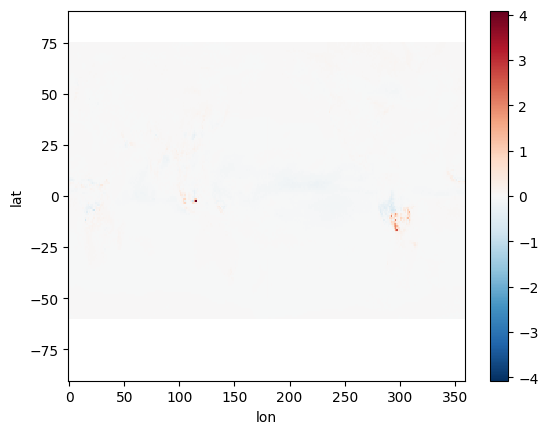

In [67]:
x =(wa6_hist_osdma8_bc['y_true_bc']-wa6_hist_osdma8_bc['y_true']).mean(dim=['time','ensemble_member'])
y = (wa6_hist_osdma8_bc['y_pred_bc']-wa6_hist_osdma8_bc['y_pred']).mean(dim=['time','ensemble_member'])
(y-x).plot()